# A Robust and Explainable Ensemble Learning Framework for Liver Disease Prediction — Complete, Leakage-Free Notebook
**TIIS-AB-2026-Apr-0612 · resubmission version**

This notebook contains the **full pipeline from the paper** (all 13 configurations, GridSearchCV tuning, feature selection, SMOTE variants, stacking, advanced hybrid, tuned advanced pipeline, multi-seed ensemble, EDA figures, SHAP) with the leakage problems removed:

| Problem in the old notebook | Fix here |
|---|---|
| SMOTE applied **before** train/test split ("Method A") | SMOTE is a pipeline step, fitted **only on each training fold** |
| SMOTE applied before `GridSearchCV` | SMOTE + feature selection live **inside** the CV pipeline |
| Ensemble weights + threshold tuned on **test** data | Chosen from **inner** out-of-fold predictions of the training fold |
| Best of 10 random splits reported | **Repeated stratified CV**, mean ± SD, same folds for all models |
| Hyper-parameters tuned once on the same split they're scored on | **Nested CV**: GridSearchCV runs inside every outer training fold |
| Only single 80/20 split, no PR-AUC / CI / calibration / subgroups | All reported (Wilcoxon + Holm, bootstrap CI, Brier, calibration, gender subgroups) |

**Run order:** top to bottom (Runtime → Run all). Results checkpoint to disk after every outer fold, so if Colab disconnects just re-run and it resumes.
**Runtime:** several minutes per outer fold on free Colab CPU. Default is 5-fold × 2 repeats. Set `N_REPEATS = 1` in the config cell for a faster run, or `SMOKE = True` for a 2-minute sanity test.

In [1]:
!pip -q install xgboost lightgbm catboost imbalanced-learn shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


## 1. Imports

In [2]:
import os, sys, json, pickle, warnings, itertools, time
from collections import Counter
from functools import partial
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import wilcoxon
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, StackingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

## 2. Configuration

In [3]:
SMOKE      = os.environ.get("SMOKE", "0") == "1"    # True -> tiny/fast sanity run (numbers meaningless)
SEED       = 42                                      # master seed (report in paper)
SEEDS      = [0, 1, 2] if not SMOKE else [0]         # seeds PER BASE LEARNER in the Multi-Seed Ensemble (report in paper)
N_SPLITS   = 5   if not SMOKE else 3                 # outer folds
N_REPEATS  = 2   if not SMOKE else 1                 # outer repeats  (set 1 for a faster run)
INNER_CV   = 3                                       # inner folds for GridSearchCV / threshold / weight search
STACK_CV   = 3                                       # internal folds of StackingClassifier (out-of-fold meta-features)
N_EST      = 200 if not SMOKE else 25                # boosting rounds / trees in boosters
FS_K       = 15                                      # features kept by Mutual-Information selection in the FS+SMOTE models
DROP_DUPES = True                                    # ILPD has duplicate rows -> duplicates across train/test would leak
N_BOOT     = 500 if not SMOKE else 50
CKPT       = "cv_checkpoint_smoke.pkl" if SMOKE else "cv_checkpoint.pkl"
DATA_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/00225/"
            "Indian%20Liver%20Patient%20Dataset%20(ILPD).csv")
DATA_CSV = os.environ.get("ILPD_CSV", "indian_liver_patient_dataset.csv")
print(dict(SMOKE=SMOKE, SEEDS=SEEDS, outer=f"{N_SPLITS}x{N_REPEATS}", inner=INNER_CV))

{'SMOKE': False, 'SEEDS': [0, 1, 2], 'outer': '5x2', 'inner': 3}


## 3. Data loading — fills the `[N = ??]`, `[F = ??]`, `[?? : ??]` placeholders in the paper

In [4]:
COLS = ["Age","Gender","Total_Bilirubin","Direct_Bilirubin","Alkaline_Phosphotase",
        "Alamine_Aminotransferase","Aspartate_Aminotransferase","Total_Proteins",
        "Albumin","Albumin_and_Globulin_Ratio","Target"]

def load_data():
    src = DATA_CSV if os.path.exists(DATA_CSV) else DATA_URL
    df = pd.read_csv(src, header=None, names=COLS)
    stats = dict(n_raw=len(df), n_dupes=int(df.duplicated().sum()),
                 n_missing=df.isna().sum()[lambda s: s > 0].to_dict())
    df["Gender"] = df["Gender"].map({"Male": 1, "Female": 0})
    df["Target"] = df["Target"].map({1: 1, 2: 0})             # 1 = liver disease, 0 = no disease
    if DROP_DUPES:
        df = df.drop_duplicates().reset_index(drop=True)
    stats.update(n_used=len(df), n_raw_features=df.shape[1] - 1,
                 disease=int((df.Target == 1).sum()), non_disease=int((df.Target == 0).sum()))
    return df, stats

df_raw, DATA_STATS = load_data()
print(json.dumps(DATA_STATS, indent=2))
print(f"\nFor the paper:  N = {DATA_STATS['n_used']} records, F = {DATA_STATS['n_raw_features']} raw attributes, "
      f"disease : non-disease = {DATA_STATS['disease']} : {DATA_STATS['non_disease']} "
      f"({DATA_STATS['disease']/DATA_STATS['n_used']:.1%} positive)")
display(df_raw.describe().T)

{
  "n_raw": 583,
  "n_dupes": 13,
  "n_missing": {
    "Albumin_and_Globulin_Ratio": 4
  },
  "n_used": 570,
  "n_raw_features": 10,
  "disease": 406,
  "non_disease": 164
}

For the paper:  N = 570 records, F = 10 raw attributes, disease : non-disease = 406 : 164 (71.2% positive)


,count,mean,std,min,25%,50%,75%,max
Age,570.0,44.849123,16.242182,4.0,33.0,45.00,58.00,90.0
Gender,570.0,0.754386,0.430829,0.0,1.0,1.00,1.00,1.0
Total_Bilirubin,570.0,3.321754,6.267941,0.4,0.8,1.00,2.60,75.0
Direct_Bilirubin,570.0,1.497544,2.833231,0.1,0.2,0.30,1.30,19.7
Alkaline_Phosphotase,570.0,291.750877,245.291859,63.0,176.0,208.00,298.00,2110.0
Alamine_Aminotransferase,570.0,79.728070,181.471697,10.0,23.0,35.00,60.00,2000.0
Aspartate_Aminotransferase,570.0,109.380702,290.880671,10.0,25.0,41.00,86.75,4929.0
Total_Proteins,570.0,6.496316,1.088300,2.7,5.8,6.60,7.20,9.6
Albumin,570.0,3.148947,0.796813,0.9,2.6,3.10,3.80,5.5
Albumin_and_Globulin_Ratio,566.0,0.948004,0.319635,0.3,0.7,0.95,1.10,2.8


## 4. Feature engineering (row-wise only → nothing is learned from data, so no leakage)
Fixes vs. the old notebook: `Enzyme_Ratio` is AST/ALT everywhere (it flipped in a later cell); duplicate columns (`Globulin` ≡ `Protein_Albumin_diff`) kept once; `Total_Proteins` spelling fixed.

In [5]:
def add_features(d):
    d = d.copy(); e = 1e-5
    d["Bilirubin_Ratio"]  = d.Direct_Bilirubin / (d.Total_Bilirubin + e)
    d["Enzyme_Ratio"]     = d.Aspartate_Aminotransferase / (d.Alamine_Aminotransferase + e)
    d["Globulin"]         = d.Total_Proteins - d.Albumin
    d["AG_ratio_calc"]    = d.Albumin / (d.Globulin + e)
    d["Age_Bilirubin"]    = d.Age * d.Total_Bilirubin
    d["Age_Enzyme"]       = d.Age * d.Alamine_Aminotransferase
    d["ALK_ALT_ratio"]    = d.Alkaline_Phosphotase / (d.Alamine_Aminotransferase + e)
    d["Total_Bili_log"]   = np.log1p(d.Total_Bilirubin)
    d["ALT_log"]          = np.log1p(d.Alamine_Aminotransferase)
    d["AST_log"]          = np.log1p(d.Aspartate_Aminotransferase)
    d["ALK_log"]          = np.log1p(d.Alkaline_Phosphotase)
    d["Enzyme_sum"]       = d.Alamine_Aminotransferase + d.Aspartate_Aminotransferase
    d["Bili_Age_interaction"] = d.Total_Bili_log * d.Age
    return d

df = add_features(df_raw)
y = df.pop("Target").values
GENDER = df["Gender"].values
FEATURES = list(df.columns)
X = df.values.astype(float)               # NaNs (A/G ratio) are imputed INSIDE each training fold
print(f"{len(FEATURES)} features after engineering ({DATA_STATS['n_raw_features']} raw + {len(FEATURES)-DATA_STATS['n_raw_features']} engineered)")

23 features after engineering (10 raw + 13 engineered)


## 5. Exploratory data analysis (Figures 1–3)

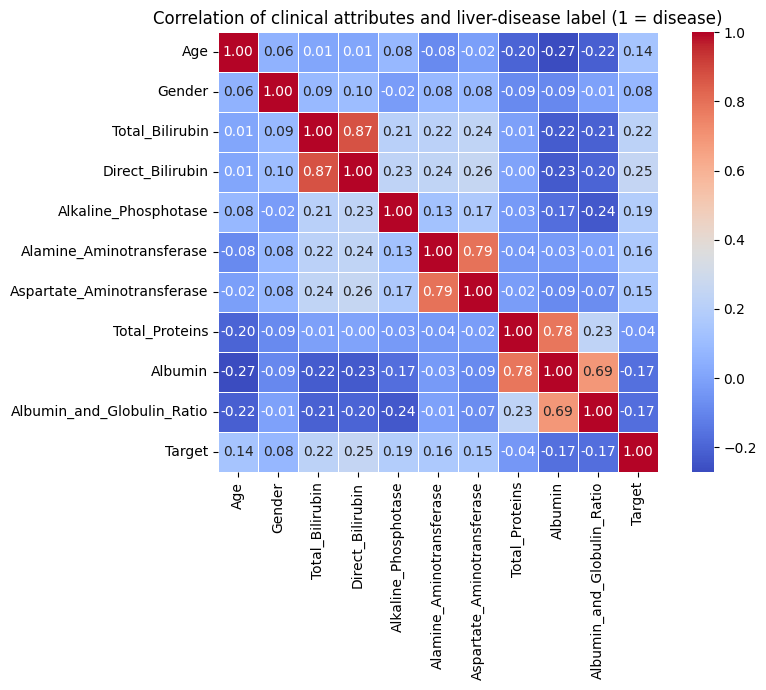

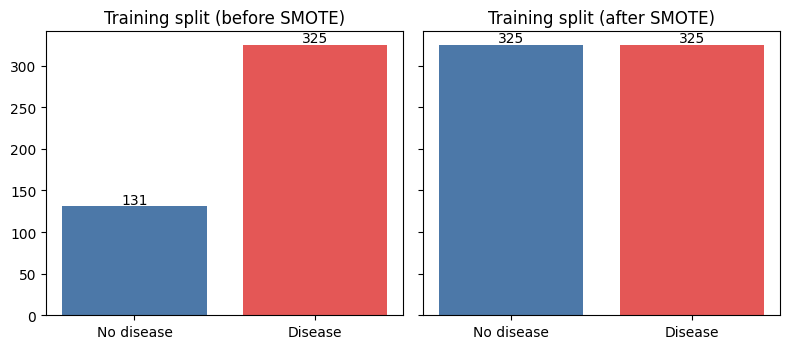

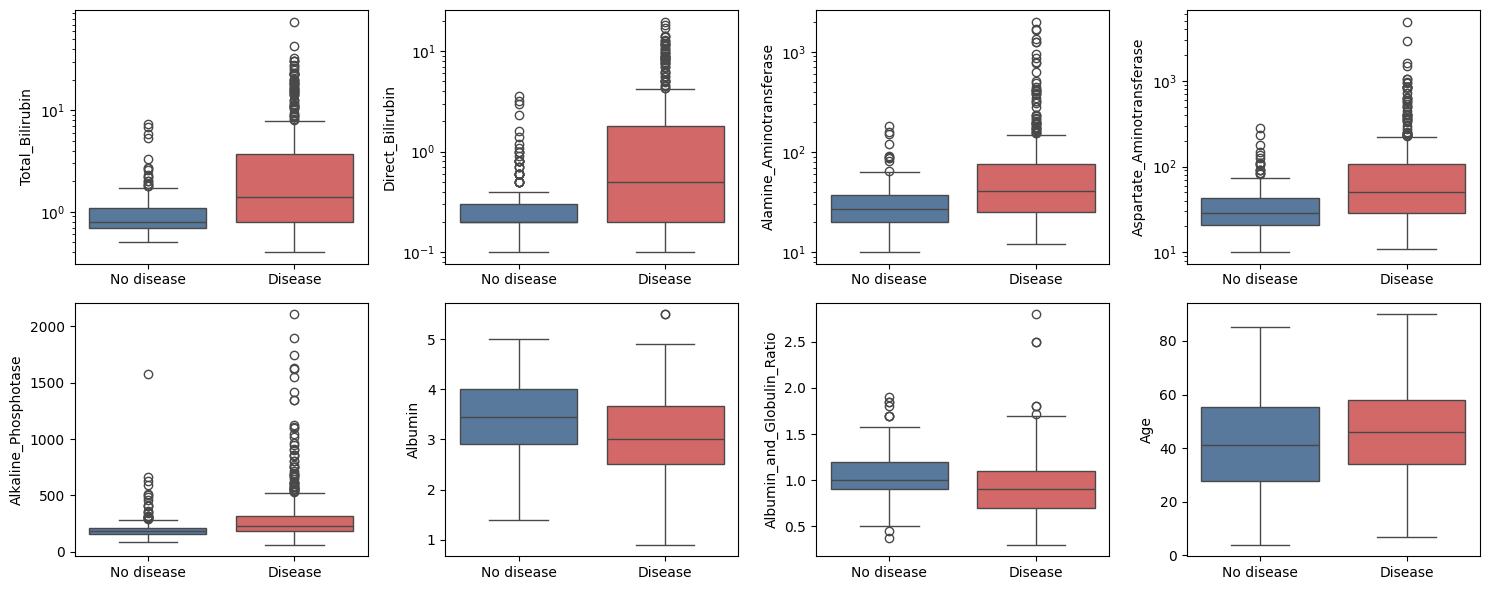

In [6]:
# Fig. 1 — correlation heatmap of the raw clinical features + target
raw = df_raw.copy()
plt.figure(figsize=(9, 7))
sns.heatmap(raw.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=.4, square=True)
plt.title("Correlation of clinical attributes and liver-disease label (1 = disease)")
plt.tight_layout(); plt.savefig("figures/fig1_correlation_heatmap.png", dpi=300); plt.show()

# Fig. 2 — class distribution before / after SMOTE (SMOTE applied to a TRAINING split only)
Xa, Xb, ya, yb = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
Xa_i = RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Xa))
_, y_sm = SMOTE(random_state=SEED).fit_resample(Xa_i, ya)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
for a, yy_, t in zip(ax, (ya, y_sm), ("Training split (before SMOTE)", "Training split (after SMOTE)")):
    c = np.bincount(yy_); a.bar(["No disease", "Disease"], c, color=["#4c78a8", "#e45756"]); a.set_title(t)
    for i, v in enumerate(c): a.text(i, v + 3, str(v), ha="center")
plt.tight_layout(); plt.savefig("figures/fig2_class_distribution_smote.png", dpi=300); plt.show()

# Fig. 3 — distributions of key attributes by class
key = ["Total_Bilirubin", "Direct_Bilirubin", "Alamine_Aminotransferase", "Aspartate_Aminotransferase",
       "Alkaline_Phosphotase", "Albumin", "Albumin_and_Globulin_Ratio", "Age"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for a, k in zip(axes.ravel(), key):
    sns.boxplot(data=raw, x="Target", y=k, ax=a, palette=["#4c78a8", "#e45756"])
    a.set_xticklabels(["No disease", "Disease"]); a.set_xlabel("")
    if raw[k].max() / max(raw[k].median(), 1e-3) > 20: a.set_yscale("log")
plt.tight_layout(); plt.savefig("figures/fig3_feature_distributions.png", dpi=300); plt.show()

## 6. Model zoo — the 13 configurations of the paper
Every model is an `imblearn` pipeline: **median imputer → RobustScaler → [SMOTE] → [Mutual-Information SelectKBest] → classifier**. All steps are re-fitted inside each training fold.
Tuned models are wrapped in `GridSearchCV` (inner stratified 3-fold, scoring = **ROC-AUC**), i.e. **nested CV** when evaluated in the outer loop.
The *SMOTE* rows also use Mutual-Information feature selection (`k` tuned over {10, 15, 20} for the tuned model), mirroring the old notebook's "FS+SMOTE" models.

In [7]:
INNER = StratifiedKFold(INNER_CV, shuffle=True, random_state=SEED)
MI = partial(mutual_info_classif, random_state=SEED)

def pipe(clf, smote=False, fs=False, k=FS_K):
    steps = [("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]
    if smote: steps.append(("smote", SMOTE(random_state=SEED)))
    if fs:    steps.append(("fs", SelectKBest(MI, k=k)))
    return ImbPipeline(steps + [("clf", clf)])

def shrink(grid):   # SMOKE mode: one value per hyper-parameter
    return {k: v[:1] for k, v in grid.items()} if SMOKE else grid

def tuned(clf, grid, **kw):
    return GridSearchCV(pipe(clf, **kw), shrink(grid), cv=INNER, scoring="roc_auc",
                        n_jobs=-1, refit=True, error_score="raise")

def bl(seed, par=1):
    """Base learners. par=1 -> single-threaded (inside GridSearchCV); par=-1 -> all cores."""
    return dict(
        lr  = LogisticRegression(C=.1, penalty="l1", solver="liblinear", max_iter=2000, random_state=seed),
        svm = SVC(C=1, probability=True, random_state=seed),
        rf  = RandomForestClassifier(n_estimators=N_EST, min_samples_leaf=2, random_state=seed, n_jobs=par),
        et  = ExtraTreesClassifier(n_estimators=N_EST*2, min_samples_leaf=2, class_weight="balanced",
                                   random_state=seed, n_jobs=par),
        xgb = XGBClassifier(n_estimators=N_EST, learning_rate=.05, max_depth=4, subsample=.8,
                            colsample_bytree=.8, eval_metric="logloss", random_state=seed,
                            n_jobs=par, verbosity=0),
        lgb = LGBMClassifier(n_estimators=N_EST, learning_rate=.05, max_depth=6, num_leaves=31,
                             subsample=.8, subsample_freq=1, colsample_bytree=.8,
                             class_weight="balanced", random_state=seed, n_jobs=par, verbose=-1),
        cb  = CatBoostClassifier(iterations=N_EST, learning_rate=.05, depth=6, l2_leaf_reg=3,
                                 auto_class_weights="Balanced", random_seed=seed, verbose=0,
                                 thread_count=par, allow_writing_files=False),
    )

# ---- FULL hyper-parameter search spaces (this is what Reviewer 1 asked for -> Table 3 of the paper) ----
GRIDS = {
 "Tuned Logistic Regression": {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100], "clf__penalty": ["l1", "l2"],
                               "clf__solver": ["liblinear"], "clf__class_weight": [None, "balanced"]},
 "Tuned Support Vector Machine": {"clf__C": [0.1, 1, 10, 100], "clf__kernel": ["linear", "rbf"],
                               "clf__gamma": ["scale", "auto"], "clf__class_weight": [None, "balanced"]},
 "Tuned Random Forest": {"clf__n_estimators": [300], "clf__max_depth": [None, 5, 10],
                               "clf__min_samples_leaf": [1, 3, 5], "clf__class_weight": [None, "balanced"]},
 "Tuned XGBoost": {"clf__n_estimators": [150, 300], "clf__max_depth": [3, 5], "clf__learning_rate": [0.03, 0.1],
                               "clf__scale_pos_weight": [1.0, 0.45]},
 "Tuned Random Forest (SMOTE)": {"clf__n_estimators": [300], "clf__max_depth": [None, 5, 10],
                               "clf__min_samples_leaf": [1, 3, 5], "fs__k": [10, 15, 20]},
 "Tuned CatBoost": {"clf__iterations": [200], "clf__depth": [3, 5, 7], "clf__learning_rate": [0.03, 0.1],
                               "clf__auto_class_weights": ["None", "Balanced"]},
 "Tuned Extra Trees": {"clf__n_estimators": [300], "clf__max_depth": [None, 6, 12],
                               "clf__min_samples_leaf": [1, 3], "clf__class_weight": [None, "balanced"]},
 "Tuned LightGBM": {"clf__num_leaves": [8, 15, 31], "clf__n_estimators": [150, 300],
                               "clf__learning_rate": [0.03, 0.1], "clf__class_weight": [None, "balanced"]},
 "Tuned Advanced Pipeline (XGB+LGBM+CatBoost)": {"clf__final_estimator__C": [0.1, 1.0, 10.0]},
}
print("Search-space sizes:", {k: int(np.prod([len(v) for v in g.values()])) for k, g in GRIDS.items()})

def stack(keys, par=1):
    b = bl(SEED, par)
    return StackingClassifier([(k, b[k]) for k in keys],
                              final_estimator=LogisticRegression(C=1.0, max_iter=2000),
                              cv=STACK_CV, stack_method="predict_proba", n_jobs=1)

Search-space sizes: {'Tuned Logistic Regression': 24, 'Tuned Support Vector Machine': 32, 'Tuned Random Forest': 18, 'Tuned XGBoost': 16, 'Tuned Random Forest (SMOTE)': 27, 'Tuned CatBoost': 12, 'Tuned Extra Trees': 12, 'Tuned LightGBM': 24, 'Tuned Advanced Pipeline (XGB+LGBM+CatBoost)': 3}


### Multi-Seed Weighted Ensemble (CatBoost + LightGBM + XGBoost + Extra Trees)
* every base learner is trained with several seeds; its probabilities are **averaged over seeds** first;
* ensemble weights **and** decision threshold are searched on **inner out-of-fold** probabilities of the *training fold only* (maximising balanced accuracy) — the test fold is never touched;
* three read-outs of the same fitted object give a **built-in ablation** (uniform weights @0.5, tuned weights @0.5, tuned weights + tuned threshold), which answers reviewer requests about threshold/weight bias.

In [8]:
class MultiSeedEnsemble(BaseEstimator, ClassifierMixin):
    KEYS = ("cb", "lgb", "xgb", "et")
    def __init__(self, seeds=(0, 1, 2), inner_splits=3, random_state=42):
        self.seeds, self.inner_splits, self.random_state = seeds, inner_splits, random_state

    @staticmethod
    def _balanced_acc_grid(y, blend, ts):
        P = blend[None, :] >= ts[:, None]
        tpr = (P & (y == 1)).sum(1) / max(1, (y == 1).sum())
        tnr = (~P & (y == 0)).sum(1) / max(1, (y == 0).sum())
        return 0.5 * (tpr + tnr)

    def _search(self, oof, y):
        ts = np.arange(0.20, 0.80, 0.01); best = (-1, None, None)
        vals = np.arange(0.1, 0.65, 0.1)
        for w in itertools.product(vals, repeat=4):
            if abs(sum(w) - 1) > 1e-9: continue
            sc = self._balanced_acc_grid(y, oof @ np.array(w), ts)
            j = int(np.argmax(sc))
            if sc[j] > best[0] + 1e-12: best = (sc[j], np.array(w), float(ts[j]))
        return best[1], best[2]

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.classes_ = np.unique(y)
        skf = StratifiedKFold(self.inner_splits, shuffle=True, random_state=self.random_state)
        oof = np.zeros((len(y), 4))
        for tr, va in skf.split(X, y):                              # inner OOF with the first seed only
            for j, k in enumerate(self.KEYS):
                oof[va, j] = bl(self.seeds[0], -1)[k].fit(X[tr], y[tr]).predict_proba(X[va])[:, 1]
        self.weights_, self.threshold_ = self._search(oof, y)        # <- chosen WITHOUT test data
        self.models_ = {k: [bl(s, -1)[k].fit(X, y) for s in self.seeds] for k in self.KEYS}
        self.mode = "tuned"
        return self

    def component_probs(self, X):
        X = np.asarray(X)
        return np.column_stack([np.mean([m.predict_proba(X)[:, 1] for m in self.models_[k]], axis=0)
                                for k in self.KEYS])
    def blend(self, comp, mode="tuned"):
        w = np.full(4, .25) if mode == "uniform" else self.weights_
        return comp @ w
    def thr(self, mode="tuned"):
        return self.threshold_ if mode == "tuned" else 0.5
    def predict_proba(self, X):
        p = self.blend(self.component_probs(X), self.mode); return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.thr(self.mode)).astype(int)

ENS = "Multi-Seed Ensemble (CB+LGBM+XGB+ET)"
ABL_U = "Ablation: Multi-Seed, uniform weights, thr=0.5"
ABL_W = "Ablation: Multi-Seed, tuned weights, thr=0.5"

def get_models():
    M = {}
    M["Tuned Logistic Regression"]       = tuned(bl(SEED)["lr"],  GRIDS["Tuned Logistic Regression"])
    M["Tuned Support Vector Machine"]    = tuned(bl(SEED)["svm"], GRIDS["Tuned Support Vector Machine"])
    M["Tuned Random Forest"]             = tuned(bl(SEED)["rf"],  GRIDS["Tuned Random Forest"])
    M["Tuned XGBoost"]                   = tuned(bl(SEED)["xgb"], GRIDS["Tuned XGBoost"])
    M["Hybrid (Stacking) Model"]         = pipe(stack(["rf", "svm", "xgb"], par=-1))
    M["Tuned Random Forest (SMOTE)"]     = tuned(bl(SEED)["rf"],  GRIDS["Tuned Random Forest (SMOTE)"], smote=True, fs=True)
    M["Hybrid (Stacking) Model (SMOTE)"] = pipe(stack(["rf", "svm", "xgb"], par=-1), smote=True, fs=True)
    M["Tuned CatBoost"]                  = tuned(bl(SEED)["cb"],  GRIDS["Tuned CatBoost"])
    M["Tuned Extra Trees"]               = tuned(bl(SEED)["et"],  GRIDS["Tuned Extra Trees"])
    M["Tuned LightGBM"]                  = tuned(bl(SEED)["lgb"], GRIDS["Tuned LightGBM"])
    M["Advanced Hybrid (CB+LGBM+XGB+ET)"] = pipe(stack(["cb", "lgb", "xgb", "et"], par=-1))
    M["Tuned Advanced Pipeline (XGB+LGBM+CatBoost)"] = tuned(stack(["xgb", "lgb", "cb"], par=1),
                                                          GRIDS["Tuned Advanced Pipeline (XGB+LGBM+CatBoost)"])
    M[ENS] = pipe(MultiSeedEnsemble(seeds=tuple(SEEDS), inner_splits=INNER_CV, random_state=SEED))
    return M
MODELS = get_models()
print(len(MODELS), "configurations:"); [print(" -", k) for k in MODELS]

13 configurations:
 - Tuned Logistic Regression
 - Tuned Support Vector Machine
 - Tuned Random Forest
 - Tuned XGBoost
 - Hybrid (Stacking) Model
 - Tuned Random Forest (SMOTE)
 - Hybrid (Stacking) Model (SMOTE)
 - Tuned CatBoost
 - Tuned Extra Trees
 - Tuned LightGBM
 - Advanced Hybrid (CB+LGBM+XGB+ET)
 - Tuned Advanced Pipeline (XGB+LGBM+CatBoost)
 - Multi-Seed Ensemble (CB+LGBM+XGB+ET)


[None, None, None, None, None, None, None, None, None, None, None, None, None]

## 7. Nested, repeated-CV evaluation (all 13 models on identical outer folds)
Checkpointed after every outer fold → safe to interrupt and re-run.

In [9]:
def fold_metrics(yt, proba, pred):
    return dict(Acc=accuracy_score(yt, pred), Prec=precision_score(yt, pred, zero_division=0),
                Rec=recall_score(yt, pred, zero_division=0), F1=f1_score(yt, pred, zero_division=0),
                BalAcc=balanced_accuracy_score(yt, pred), ROC_AUC=roc_auc_score(yt, proba),
                PR_AUC=average_precision_score(yt, proba), Brier=brier_score_loss(yt, proba))

rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
FOLDS = list(rskf.split(X, y))
if os.path.exists(CKPT):
    ck = pickle.load(open(CKPT, "rb")); print(f"Resuming: {len(ck['done'])}/{len(FOLDS)} outer folds already done")
else:
    ck = dict(done=[], rows=[], oof={}, params={}, ens_info=[])

def record(name, i, te, yt, proba, pred):
    ck["rows"].append(dict(model=name, fold=i, **fold_metrics(yt, proba, pred)))
    ck["oof"].setdefault(name, []).append((te, proba, pred))

t0 = time.time()
for i, (tr, te) in enumerate(FOLDS):
    if i in ck["done"]: continue
    for name, est in MODELS.items():
        try:
            m = clone(est).fit(X[tr], y[tr])
            if name == ENS:
                Xt = X[te]
                for _, step in m.steps[:-1]: Xt = step.transform(Xt)   # fitted imputer + scaler (no SMOTE in this pipeline)
                clf = m.named_steps["clf"]; comp = clf.component_probs(Xt)
                for lab, mode in ((ENS, "tuned"), (ABL_W, "weights"), (ABL_U, "uniform")):
                    p = clf.blend(comp, "uniform" if mode == "uniform" else "tuned")
                    pred = (p >= clf.thr("tuned" if mode == "tuned" else "x")).astype(int)
                    record(lab, i, te, y[te], p, pred)
                ck["ens_info"].append(dict(fold=i, weights=dict(zip(clf.KEYS, clf.weights_.round(2))), threshold=clf.threshold_))
            else:
                proba = m.predict_proba(X[te])[:, 1]; pred = m.predict(X[te])
                record(name, i, te, y[te], proba, pred)
                if hasattr(m, "best_params_"):
                    ck["params"].setdefault(name, []).append(m.best_params_)
        except Exception as e:
            print(f"  !! {name} failed on fold {i}: {type(e).__name__}: {str(e)[:120]}")
    ck["done"].append(i); pickle.dump(ck, open(CKPT, "wb"))
    print(f"outer fold {i+1}/{len(FOLDS)} done  ({(time.time()-t0)/60:.1f} min elapsed)", flush=True)

outer fold 1/10 done  (4.7 min elapsed)
outer fold 2/10 done  (8.9 min elapsed)
outer fold 3/10 done  (12.8 min elapsed)
outer fold 4/10 done  (16.7 min elapsed)
outer fold 5/10 done  (20.9 min elapsed)
outer fold 6/10 done  (25.1 min elapsed)
outer fold 7/10 done  (29.0 min elapsed)
outer fold 8/10 done  (33.2 min elapsed)
outer fold 9/10 done  (37.2 min elapsed)
outer fold 10/10 done  (41.2 min elapsed)


## 8. Results — Table 2 (mean ± SD over outer folds), now with PR-AUC and Brier score

In [10]:
res = pd.DataFrame(ck["rows"])
METS = ["Acc", "Prec", "Rec", "F1", "BalAcc", "ROC_AUC", "PR_AUC", "Brier"]
MAIN = [m for m in res.model.unique() if not m.startswith("Ablation")]
g = res.groupby("model")[METS]; mean_, sd_ = g.mean(), g.std(ddof=1)
table2 = (mean_ * 100).round(2).astype(str) + " ± " + (sd_ * 100).round(2).astype(str)
table2["Brier"] = mean_["Brier"].round(3).astype(str) + " ± " + sd_["Brier"].round(3).astype(str)
order = mean_.loc[MAIN].sort_values("ROC_AUC", ascending=False).index.tolist()
print(f"Outer CV: {N_SPLITS}-fold x {N_REPEATS} repeats = {len(FOLDS)} folds; all values in % except Brier\n")
display(table2.loc[order]); table2.loc[order].to_csv("table2_main_results.csv")
print("\nBuilt-in ablation of the ensemble (threshold / weighting):")
display(table2.loc[[ENS, ABL_W, ABL_U]])
res.to_csv("cv_results_per_fold.csv", index=False)

Outer CV: 5-fold x 2 repeats = 10 folds; all values in % except Brier



,Acc,Prec,Rec,F1,BalAcc,ROC_AUC,PR_AUC,Brier
model,,,,,,,,
Advanced Hybrid (CB+LGBM+XGB+ET),71.93 ± 2.8,73.06 ± 1.79,96.06 ± 2.89,82.97 ± 1.75,54.13 ± 3.75,75.79 ± 3.26,89.62 ± 1.44,0.175 ± 0.008
Multi-Seed Ensemble (CB+LGBM+XGB+ET),64.82 ± 4.65,88.83 ± 2.69,58.0 ± 7.59,69.89 ± 5.4,69.84 ± 3.29,75.71 ± 3.64,89.49 ± 1.75,0.178 ± 0.014
Tuned Extra Trees,69.47 ± 4.49,78.21 ± 6.84,82.05 ± 15.99,78.65 ± 6.03,60.27 ± 7.65,75.03 ± 3.39,89.31 ± 1.52,0.181 ± 0.015
Tuned Logistic Regression,68.68 ± 4.07,81.72 ± 8.03,75.3 ± 15.89,76.76 ± 5.71,63.96 ± 8.83,74.79 ± 3.05,89.44 ± 1.29,0.189 ± 0.011
Tuned Advanced Pipeline (XGB+LGBM+CatBoost),70.88 ± 0.81,71.95 ± 1.28,97.04 ± 3.74,82.58 ± 0.8,51.56 ± 2.77,74.44 ± 3.01,88.52 ± 1.71,0.183 ± 0.005
Hybrid (Stacking) Model,70.7 ± 2.87,72.37 ± 1.91,95.32 ± 2.07,82.26 ± 1.67,52.54 ± 4.13,74.25 ± 3.37,88.75 ± 1.65,0.181 ± 0.009
Tuned CatBoost,69.39 ± 3.22,78.28 ± 5.33,80.42 ± 10.82,78.66 ± 3.7,61.27 ± 6.75,74.2 ± 4.07,88.66 ± 2.01,0.185 ± 0.018
Tuned Random Forest,68.77 ± 4.06,77.8 ± 5.22,80.21 ± 11.69,78.22 ± 4.45,60.46 ± 7.34,74.05 ± 3.29,88.76 ± 1.32,0.183 ± 0.011
Tuned LightGBM,70.26 ± 3.19,79.67 ± 4.09,79.07 ± 8.87,78.93 ± 3.4,63.77 ± 5.3,74.05 ± 2.64,88.26 ± 1.26,0.191 ± 0.017



Built-in ablation of the ensemble (threshold / weighting):


,Acc,Prec,Rec,F1,BalAcc,ROC_AUC,PR_AUC,Brier
model,,,,,,,,
Multi-Seed Ensemble (CB+LGBM+XGB+ET),64.82 ± 4.65,88.83 ± 2.69,58.0 ± 7.59,69.89 ± 5.4,69.84 ± 3.29,75.71 ± 3.64,89.49 ± 1.75,0.178 ± 0.014
"Ablation: Multi-Seed, tuned weights, thr=0.5",71.58 ± 3.29,80.29 ± 2.76,79.81 ± 4.63,79.96 ± 2.55,65.53 ± 4.13,75.71 ± 3.64,89.49 ± 1.75,0.178 ± 0.014
"Ablation: Multi-Seed, uniform weights, thr=0.5",72.37 ± 3.99,80.64 ± 3.3,80.67 ± 3.39,80.61 ± 2.79,66.26 ± 5.36,75.54 ± 3.34,89.35 ± 1.65,0.18 ± 0.013


### Table 3 — selected hyper-parameters (most frequent winner across outer folds) and search spaces

In [11]:
rows = []
for name, plist in ck["params"].items():
    cnt = Counter(json.dumps(p, sort_keys=True, default=str) for p in plist)
    best, n = cnt.most_common(1)[0]
    rows.append(dict(Model=name, Selected=best, Chosen_in=f"{n}/{len(plist)} folds",
                     Search_space=json.dumps(GRIDS.get(name, {}), default=str)))
t3 = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 200); display(t3)
t3.to_csv("table3_hyperparameters.csv", index=False)
print("\nMulti-Seed Ensemble — weights/threshold chosen on INNER folds, per outer fold:")
display(pd.DataFrame(ck["ens_info"]))
thr = [d["threshold"] for d in ck["ens_info"]]
print(f"threshold mean={np.mean(thr):.3f} sd={np.std(thr):.3f} range=({min(thr):.2f},{max(thr):.2f})")

,Model,Selected,Chosen_in,Search_space
0,Tuned Logistic Regression,"{""clf__C"": 0.001, ""clf__class_weight"": ""balanced"", ""clf__penalty"": ""l2"", ""clf__solver"": ""liblinear""}",3/10 folds,"{""clf__C"": [0.001, 0.01, 0.1, 1, 10, 100], ""clf__penalty"": [""l1"", ""l2""], ""clf__solver"": [""liblinear""], ""clf__class_weight"": [null, ""balanced""]}"
1,Tuned Support Vector Machine,"{""clf__C"": 0.1, ""clf__class_weight"": ""balanced"", ""clf__gamma"": ""scale"", ""clf__kernel"": ""linear""}",4/10 folds,"{""clf__C"": [0.1, 1, 10, 100], ""clf__kernel"": [""linear"", ""rbf""], ""clf__gamma"": [""scale"", ""auto""], ""clf__class_weight"": [null, ""balanced""]}"
2,Tuned Random Forest,"{""clf__class_weight"": ""balanced"", ""clf__max_depth"": 10, ""clf__min_samples_leaf"": 3, ""clf__n_estimators"": 300}",2/10 folds,"{""clf__n_estimators"": [300], ""clf__max_depth"": [null, 5, 10], ""clf__min_samples_leaf"": [1, 3, 5], ""clf__class_weight"": [null, ""balanced""]}"
3,Tuned XGBoost,"{""clf__learning_rate"": 0.03, ""clf__max_depth"": 3, ""clf__n_estimators"": 150, ""clf__scale_pos_weight"": 0.45}",4/10 folds,"{""clf__n_estimators"": [150, 300], ""clf__max_depth"": [3, 5], ""clf__learning_rate"": [0.03, 0.1], ""clf__scale_pos_weight"": [1.0, 0.45]}"
4,Tuned Random Forest (SMOTE),"{""clf__max_depth"": null, ""clf__min_samples_leaf"": 1, ""clf__n_estimators"": 300, ""fs__k"": 20}",2/10 folds,"{""clf__n_estimators"": [300], ""clf__max_depth"": [null, 5, 10], ""clf__min_samples_leaf"": [1, 3, 5], ""fs__k"": [10, 15, 20]}"
5,Tuned CatBoost,"{""clf__auto_class_weights"": ""None"", ""clf__depth"": 3, ""clf__iterations"": 200, ""clf__learning_rate"": 0.03}",4/10 folds,"{""clf__iterations"": [200], ""clf__depth"": [3, 5, 7], ""clf__learning_rate"": [0.03, 0.1], ""clf__auto_class_weights"": [""None"", ""Balanced""]}"
6,Tuned Extra Trees,"{""clf__class_weight"": null, ""clf__max_depth"": null, ""clf__min_samples_leaf"": 3, ""clf__n_estimators"": 300}",3/10 folds,"{""clf__n_estimators"": [300], ""clf__max_depth"": [null, 6, 12], ""clf__min_samples_leaf"": [1, 3], ""clf__class_weight"": [null, ""balanced""]}"
7,Tuned LightGBM,"{""clf__class_weight"": ""balanced"", ""clf__learning_rate"": 0.03, ""clf__n_estimators"": 150, ""clf__num_leaves"": 8}",3/10 folds,"{""clf__num_leaves"": [8, 15, 31], ""clf__n_estimators"": [150, 300], ""clf__learning_rate"": [0.03, 0.1], ""clf__class_weight"": [null, ""balanced""]}"
8,Tuned Advanced Pipeline (XGB+LGBM+CatBoost),"{""clf__final_estimator__C"": 0.1}",6/10 folds,"{""clf__final_estimator__C"": [0.1, 1.0, 10.0]}"



Multi-Seed Ensemble — weights/threshold chosen on INNER folds, per outer fold:


,fold,weights,threshold
0,0,"{'cb': 0.1, 'lgb': 0.1, 'xgb': 0.2, 'et': 0.6}",0.58
1,1,"{'cb': 0.4, 'lgb': 0.1, 'xgb': 0.1, 'et': 0.4}",0.69
2,2,"{'cb': 0.1, 'lgb': 0.4, 'xgb': 0.2, 'et': 0.3}",0.75
3,3,"{'cb': 0.1, 'lgb': 0.1, 'xgb': 0.4, 'et': 0.4}",0.77
4,4,"{'cb': 0.2, 'lgb': 0.1, 'xgb': 0.1, 'et': 0.6}",0.64
5,5,"{'cb': 0.3, 'lgb': 0.1, 'xgb': 0.1, 'et': 0.5}",0.70
6,6,"{'cb': 0.1, 'lgb': 0.1, 'xgb': 0.3, 'et': 0.5}",0.71
7,7,"{'cb': 0.2, 'lgb': 0.5, 'xgb': 0.2, 'et': 0.1}",0.74
8,8,"{'cb': 0.1, 'lgb': 0.1, 'xgb': 0.2, 'et': 0.6}",0.76
9,9,"{'cb': 0.1, 'lgb': 0.2, 'xgb': 0.1, 'et': 0.6}",0.76


threshold mean=0.710 sd=0.058 range=(0.58,0.77)


## 9. Statistical tests, bootstrap CIs, calibration, subgroup analysis

In [12]:
# --- paired Wilcoxon vs the Multi-Seed Ensemble, Holm-corrected (per-outer-fold ROC-AUC and PR-AUC) ---
def holm(p):
    p = np.array(p); o = np.argsort(p); adj = np.empty_like(p); run = 0
    for r, i in enumerate(o): run = max(run, (len(p) - r) * p[i]); adj[i] = min(1, run)
    return adj
ref = res[res.model == ENS].set_index("fold"); out = []
for k in ("ROC_AUC", "PR_AUC"):
    names, ps = [], []
    for nme in MAIN:
        if nme == ENS: continue
        o = res[res.model == nme].set_index("fold")
        try: ps.append(wilcoxon(ref[k], o[k]).pvalue); names.append(nme)
        except ValueError: pass
    out.append(pd.DataFrame({"model": names, f"p_{k}": ps, f"p_{k}_Holm": holm(ps)}).set_index("model"))
display(pd.concat(out, axis=1).round(4))
print("NOTE: outer folds overlap in training data, so fold-wise tests are optimistic; interpret as supporting, not definitive.")

# --- pooled out-of-fold predictions (average over repeats) ---
def pooled(name):
    P = {}
    for te, p, pr in ck["oof"][name]:
        for a, b, c in zip(te, p, pr): P.setdefault(a, []).append((b, c))
    idx = np.array(sorted(P))
    return idx, np.array([np.mean([t[0] for t in P[i]]) for i in idx]), \
           (np.array([np.mean([t[1] for t in P[i]]) for i in idx]) >= .5).astype(int), y[idx]

# --- bootstrap 95% CI (resampling PATIENTS) for every main model ---
rng = np.random.default_rng(SEED); ci_rows = []
for nme in order:
    idx, pm, pdc, yy = pooled(nme); bs = []
    for _ in range(N_BOOT):
        s = rng.integers(0, len(idx), len(idx))
        if len(np.unique(yy[s])) < 2: continue
        bs.append((accuracy_score(yy[s], pdc[s]), roc_auc_score(yy[s], pm[s]), average_precision_score(yy[s], pm[s])))
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    ci_rows.append(dict(model=nme, **{f"{k} 95% CI": f"[{a:.3f}, {b:.3f}]" for k, a, b in zip(("Acc", "ROC-AUC", "PR-AUC"), lo, hi)}))
ci_df = pd.DataFrame(ci_rows).set_index("model"); display(ci_df); ci_df.to_csv("table_bootstrap_ci.csv")

# --- best model by mean ROC-AUC: calibration + gender subgroup ---
BEST = order[0]; print("Best main model by CV ROC-AUC:", BEST)
idx, pm, pdc, yy = pooled(BEST)
fp, mp = calibration_curve(yy, pm, n_bins=8, strategy="quantile")
print(f"Brier = {brier_score_loss(yy, pm):.4f}")
print("\nSubgroup performance (pooled out-of-fold):")
gg = GENDER[idx]; sub = []
for lab, nm in ((1, "Male"), (0, "Female")):
    mk = gg == lab
    sub.append(dict(group=nm, n=int(mk.sum()), prevalence=round(float(yy[mk].mean()), 3), Acc=round(float(accuracy_score(yy[mk], pdc[mk])), 3),
                    Recall=round(float(recall_score(yy[mk], pdc[mk])), 3), Precision=round(float(precision_score(yy[mk], pdc[mk], zero_division=0)), 3),
                    ROC_AUC=round(float(roc_auc_score(yy[mk], pm[mk])), 3)))
for lo_, hi_, nm in ((0, 40, "Age<40"), (40, 55, "Age 40-54"), (55, 200, "Age>=55")):
    mk = (df.Age.values[idx] >= lo_) & (df.Age.values[idx] < hi_)
    if mk.sum() > 10 and len(np.unique(yy[mk])) == 2:
        sub.append(dict(group=nm, n=int(mk.sum()), prevalence=round(float(yy[mk].mean()), 3), Acc=round(float(accuracy_score(yy[mk], pdc[mk])), 3),
                        Recall=round(float(recall_score(yy[mk], pdc[mk])), 3), Precision=round(float(precision_score(yy[mk], pdc[mk], zero_division=0)), 3),
                        ROC_AUC=round(float(roc_auc_score(yy[mk], pm[mk])), 3)))
display(pd.DataFrame(sub)); pd.DataFrame(sub).to_csv("table_subgroups.csv", index=False)

,p_ROC_AUC,p_ROC_AUC_Holm,p_PR_AUC,p_PR_AUC_Holm
model,,,,
Tuned Logistic Regression,0.2754,0.5508,1.0000,1.0000
Tuned Support Vector Machine,0.0273,0.1641,0.0137,0.0684
Tuned Random Forest,0.0020,0.0234,0.0098,0.0586
Tuned XGBoost,0.0137,0.1230,0.0059,0.0527
Hybrid (Stacking) Model,0.0098,0.0977,0.0059,0.0527
Tuned Random Forest (SMOTE),0.0059,0.0645,0.0059,0.0527
Hybrid (Stacking) Model (SMOTE),0.0195,0.1367,0.0020,0.0234
Tuned CatBoost,0.0840,0.3359,0.0645,0.2578
Tuned Extra Trees,0.1602,0.4805,0.5566,1.0000


NOTE: outer folds overlap in training data, so fold-wise tests are optimistic; interpret as supporting, not definitive.


,Acc 95% CI,ROC-AUC 95% CI,PR-AUC 95% CI
model,,,
Advanced Hybrid (CB+LGBM+XGB+ET),"[0.682, 0.755]","[0.715, 0.797]","[0.872, 0.918]"
Multi-Seed Ensemble (CB+LGBM+XGB+ET),"[0.637, 0.716]","[0.719, 0.799]","[0.868, 0.919]"
Tuned Extra Trees,"[0.671, 0.747]","[0.701, 0.781]","[0.863, 0.913]"
Tuned Logistic Regression,"[0.665, 0.738]","[0.692, 0.776]","[0.857, 0.913]"
Tuned Advanced Pipeline (XGB+LGBM+CatBoost),"[0.671, 0.742]","[0.705, 0.785]","[0.846, 0.910]"
Hybrid (Stacking) Model,"[0.675, 0.751]","[0.698, 0.778]","[0.837, 0.907]"
Tuned CatBoost,"[0.665, 0.745]","[0.691, 0.777]","[0.846, 0.912]"
Tuned Random Forest,"[0.663, 0.739]","[0.697, 0.774]","[0.856, 0.910]"
Tuned LightGBM,"[0.682, 0.754]","[0.700, 0.777]","[0.846, 0.910]"


Best main model by CV ROC-AUC: Advanced Hybrid (CB+LGBM+XGB+ET)
Brier = 0.1742

Subgroup performance (pooled out-of-fold):


,group,n,prevalence,Acc,Recall,Precision,ROC_AUC
0,Male,430,0.733,0.744,0.984,0.747,0.788
1,Female,140,0.650,0.643,0.978,0.650,0.643
2,Age<40,217,0.631,0.645,0.964,0.647,0.698
3,Age 40-54,179,0.777,0.777,0.986,0.783,0.742
4,Age>=55,174,0.747,0.753,1.000,0.751,0.837


## 10. Result figures (Figures 4–6, readable replacements for the illegible originals)

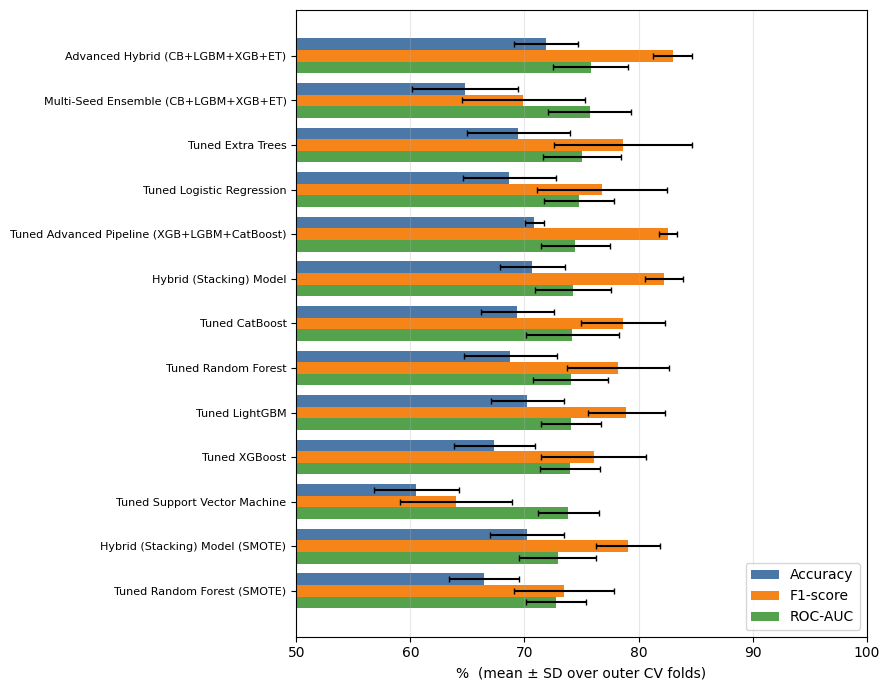

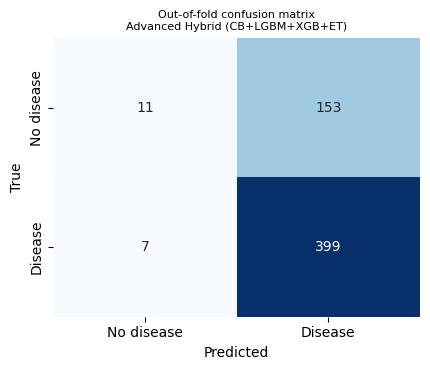

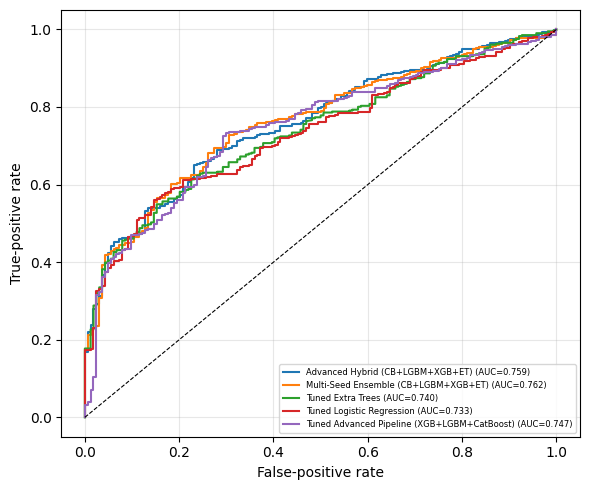

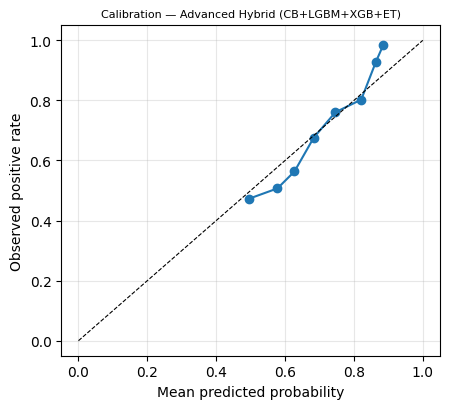

In [13]:
# Fig. 4 — model comparison: horizontal bars, abbreviated labels, error bars = SD over outer folds
short = {n: f"M{i+1}" for i, n in enumerate(MAIN)}
fig, ax = plt.subplots(figsize=(9, 7)); ypos = np.arange(len(order)); h = .26
for j, (k, c) in enumerate((("Acc", "#4c78a8"), ("F1", "#f58518"), ("ROC_AUC", "#54a24b"))):
    ax.barh(ypos + (j - 1) * h, mean_.loc[order, k] * 100, h, xerr=sd_.loc[order, k] * 100, color=c,
            label={"Acc": "Accuracy", "F1": "F1-score", "ROC_AUC": "ROC-AUC"}[k], capsize=2)
ax.set_yticks(ypos); ax.set_yticklabels(order, fontsize=8); ax.invert_yaxis(); ax.set_xlim(50, 100)
ax.set_xlabel("%  (mean ± SD over outer CV folds)"); ax.legend(loc="lower right"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig("figures/fig4_model_comparison.png", dpi=300); plt.show()

# Fig. 5 — confusion matrix of the best model (pooled out-of-fold predictions)
cm = confusion_matrix(yy, pdc)
plt.figure(figsize=(4.4, 3.8)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Out-of-fold confusion matrix\n{BEST}", fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig5_confusion_matrix.png", dpi=300); plt.show()

# Fig. 6 — ROC curves, top-5 models (pooled out-of-fold probabilities)
plt.figure(figsize=(6, 5))
for nme in order[:5]:
    ii, pp, _, yt_ = pooled(nme); fpr, tpr, _ = roc_curve(yt_, pp)
    plt.plot(fpr, tpr, label=f"{nme} (AUC={roc_auc_score(yt_, pp):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=.8); plt.xlabel("False-positive rate"); plt.ylabel("True-positive rate")
plt.legend(fontsize=6, loc="lower right"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/fig6_roc_curves.png", dpi=300); plt.show()

# Extra — calibration (reliability) plot of the best model
plt.figure(figsize=(4.6, 4.2)); plt.plot(mp, fp, "o-"); plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed positive rate"); plt.title(f"Calibration — {BEST}", fontsize=8)
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("figures/fig_calibration.png", dpi=300); plt.show()

## 11. SHAP explainability (Figures 7–8)
Fitted on a stratified 80/20 split with imputer/scaler fitted on the training part only. SHAP explains the **CatBoost member** of the ensemble (TreeExplainer is exact for trees; exact SHAP for the whole weighted ensemble would require a model-agnostic explainer).
**SHAP importance = predictive association learned by the model, not clinical causation** — keep this wording in the paper.

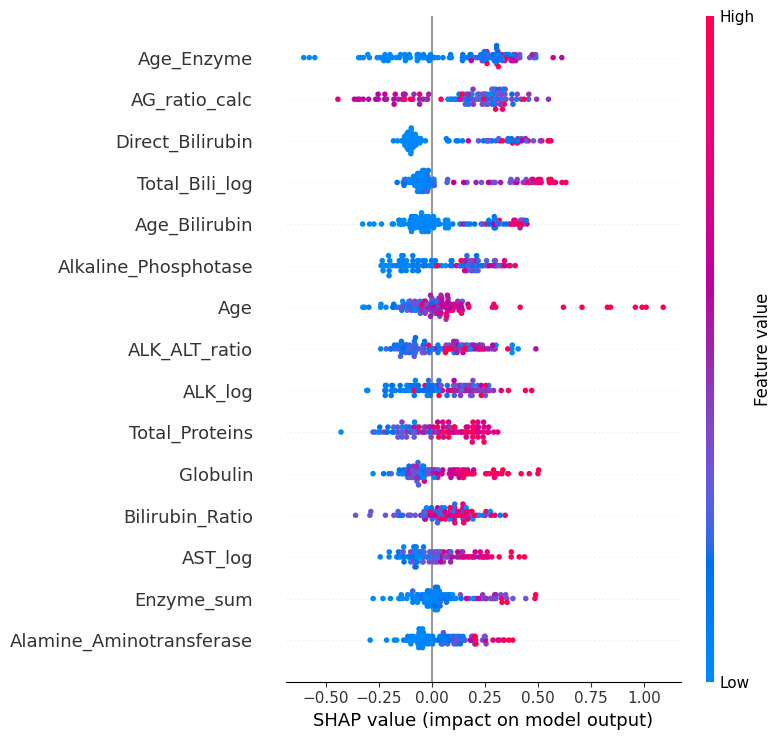

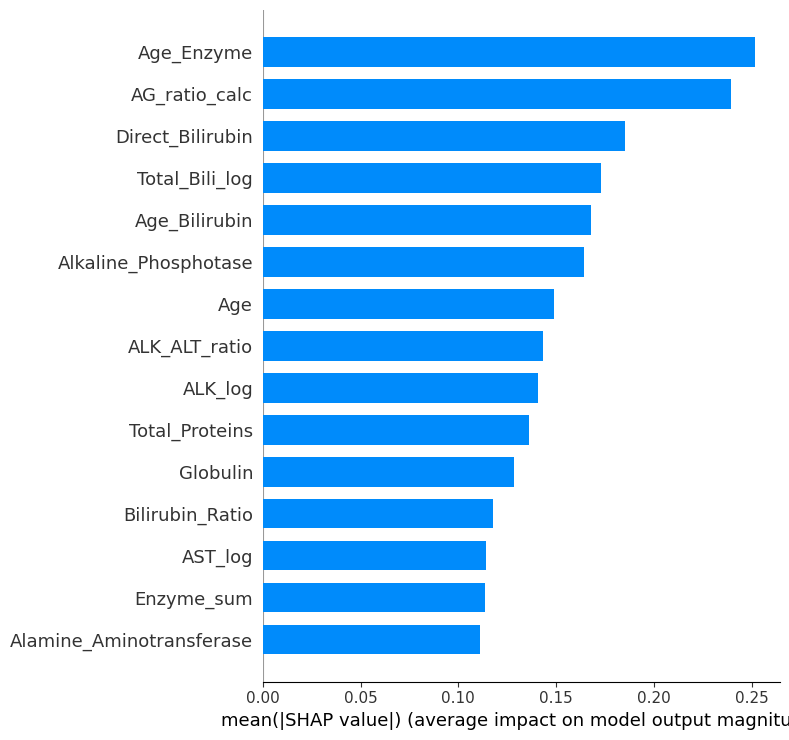

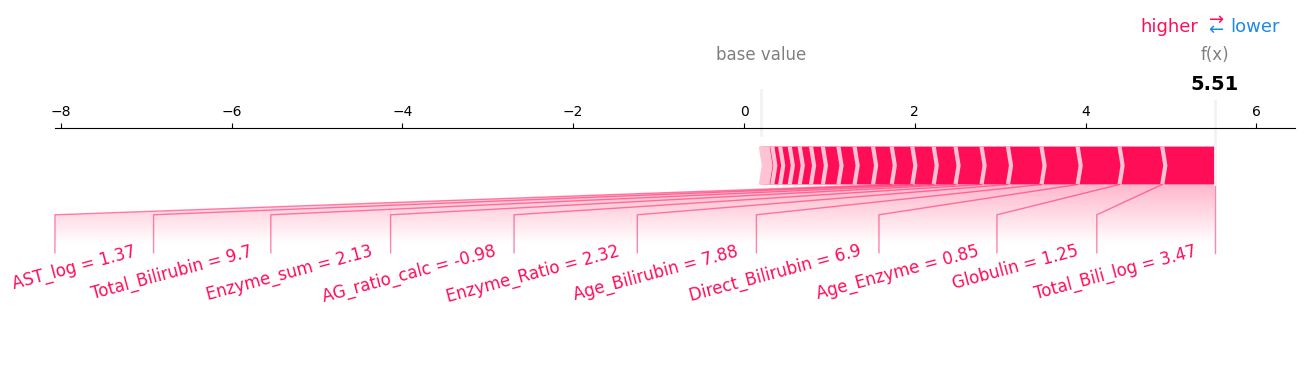

Top-10 mean |SHAP|:


,mean|SHAP|
Age_Enzyme,0.2520
AG_ratio_calc,0.2394
Direct_Bilirubin,0.1855
Total_Bili_log,0.1729
Age_Bilirubin,0.1681
Alkaline_Phosphotase,0.1641
Age,0.1489
ALK_ALT_ratio,0.1435
ALK_log,0.1407
Total_Proteins,0.1362


In [14]:
import shap
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
imp = SimpleImputer(strategy="median").fit(Xtr); sc = RobustScaler().fit(imp.transform(Xtr))
Xtr_s = pd.DataFrame(sc.transform(imp.transform(Xtr)), columns=FEATURES)
Xte_s = pd.DataFrame(sc.transform(imp.transform(Xte)), columns=FEATURES)
cb = bl(SEED, -1)["cb"].fit(Xtr_s, ytr)
expl = shap.TreeExplainer(cb); sv = expl.shap_values(Xte_s)

plt.figure(); shap.summary_plot(sv, Xte_s, max_display=15, show=False)
plt.tight_layout(); plt.savefig("figures/fig8_shap_summary.png", dpi=300, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(sv, Xte_s, plot_type="bar", max_display=15, show=False)
plt.tight_layout(); plt.savefig("figures/fig8b_shap_bar.png", dpi=300, bbox_inches="tight"); plt.show()

# Fig. 7 — force plot for one representative patient (high-resolution, a few features to avoid overlapping text)
try:
    i0 = int(np.argmax(cb.predict_proba(Xte_s)[:, 1]))
    shap.force_plot(expl.expected_value, sv[i0], Xte_s.iloc[i0].round(2), matplotlib=True, show=False,
                    figsize=(16, 3.2), text_rotation=15, contribution_threshold=0.05)
    plt.savefig("figures/fig7_shap_force.png", dpi=300, bbox_inches="tight"); plt.show()
except Exception as e:
    print("force plot skipped:", e)
top = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False).head(10)
print("Top-10 mean |SHAP|:"); display(top.round(4).to_frame("mean|SHAP|"))

## 12. Reproducibility block (paste into “Experimental Setup”)

In [15]:
import sklearn, xgboost, lightgbm, catboost, imblearn, scipy
env = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
           scikit_learn=sklearn.__version__, xgboost=xgboost.__version__, lightgbm=lightgbm.__version__,
           catboost=catboost.__version__, imbalanced_learn=imblearn.__version__, shap=shap.__version__,
           master_seed=SEED, multi_seed_ensemble_seeds=SEEDS, outer_cv=f"{N_SPLITS}-fold x {N_REPEATS} repeated stratified",
           inner_cv=f"{INNER_CV}-fold stratified (GridSearchCV, scoring=roc_auc)", stacking_cv=STACK_CV,
           smote="fit inside each training fold only", feature_selection=f"MutualInfo SelectKBest, k tuned in {{10,15,20}} (RF-SMOTE) / {FS_K} (stacking-SMOTE)",
           dedup=DROP_DUPES, dataset=DATA_STATS)
print(json.dumps(env, indent=2, default=str)); json.dump(env, open("environment_and_data_stats.json", "w"), indent=2, default=str)

{
  "python": "3.13.16",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "scikit_learn": "1.6.1",
  "xgboost": "3.4.1",
  "lightgbm": "4.6.0",
  "catboost": "1.2.10",
  "imbalanced_learn": "0.14.2",
  "shap": "0.52.0",
  "master_seed": 42,
  "multi_seed_ensemble_seeds": [
    0,
    1,
    2
  ],
  "outer_cv": "5-fold x 2 repeated stratified",
  "inner_cv": "3-fold stratified (GridSearchCV, scoring=roc_auc)",
  "stacking_cv": 3,
  "smote": "fit inside each training fold only",
  "feature_selection": "MutualInfo SelectKBest, k tuned in {10,15,20} (RF-SMOTE) / 15 (stacking-SMOTE)",
  "dedup": true,
  "dataset": {
    "n_raw": 583,
    "n_dupes": 13,
    "n_missing": {
      "Albumin_and_Globulin_Ratio": 4
    },
    "n_used": 570,
    "n_raw_features": 10,
    "disease": 406,
    "non_disease": 164
  }
}


## 13. How this maps to your paper — edits to make before resubmission

1. **Abstract / Conclusion / Results text:** replace 93.41 % / 97.07 % with the new nested-CV numbers from Table 2 (and the bootstrap CIs). Do **not** claim the Multi-Seed Ensemble is best unless it still is; the ablation rows show how much comes from weighting vs. threshold.
2. **Table 2:** use `table2_main_results.csv` — now includes the previously missing *Tuned Advanced Pipeline* row and PR-AUC / Brier columns.
3. **Table 3 + Step 6:** use `table3_hyperparameters.csv` (selected values **and** the full search space).
4. **Experimental Setup:** paste the JSON from section 12 (Python version, package versions, seeds, CV design). Remove all `[Author: ...]` notes.
5. **Methodology wording to correct:** the code uses **Mutual-Information `SelectKBest`** (not RFE) — either say that, or add RFE. Say that SMOTE and feature selection are fit inside each training fold (now true). The two *SMOTE* rows also use feature selection, so the SMOTE effect there is confounded with FS (say so, or add an FS-only row).
6. **Limitations:** keep the single-dataset / no-external-validation statement; add that fold-wise significance tests are optimistic due to overlapping training sets, and that class-weighted probabilities are not calibrated (see calibration plot).
7. **Figures:** replace Figs. 1–8 with files in `figures/` (new Fig. 4 is horizontal and legible; Fig. 7 force plot regenerated; Fig. 2 SMOTE is shown on a training split only). Verify captions against the new images.
8. **Response letter:** state openly that the original 93.41 % was produced by SMOTE-before-split with test-tuned weights/threshold and best-of-10-splits selection, and that all results were recomputed with nested repeated CV.